# Step 09 check: do the DL picks sit on the arrivals?

Independent verification of step 09 (scautopick + scdlrtpicker on the 11 Gwangyang events).
This notebook shows **4 waveform examples: 2 events x 2 stations** (one HH broadband, one HG accelerometer), with

- the **PhaseNet+ reference picks** (blue, solid),
- the picks of **phasenet_original** (the best model of step 09; vermillion, dashed),
- the picks of **phasenet_instance** (the second model; green, dotted).

**Station rule, fixed before looking at any waveform:** per event, the HH and the HG station closest to 40 km
epicentral distance that have both a PhaseNet+ P and S pick, whether or not a DL model picked there.
**Events:** the largest event (ML 2.2, KMA id 20210827220322; HYPOINVERSE origin 22:03:23.19 UTC) and one of the
two smallest (ML 1.1, KMA id 20260203021535; HYPOINVERSE origin 02:15:35.87 UTC; step 09 found this event the hardest).

**Traces:** raw counts of the bound sensor from the sorted playback file the picker read, demeaned.
Overview: one-pass (causal) 5-20 Hz Butterworth band-pass, 4 corners, each component scaled to its own peak.
Zooms: the raw (unfiltered, demeaned) trace in gray above the causal 5-20 Hz trace in black, each scaled to
its own peak inside the zoom window. A causal filter puts no energy ahead of the onset (a zero-phase filter would),
but it delays the later wiggles; the raw trace shows the onset without any filter.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import obspy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from lxml import etree

PROJECT='/home/msseo/works/74.SeisComP_rtDD_DLpicker'
DATA=f'{PROJECT}/data/gwangyang_11ev'
RUN09=f'{PROJECT}/runs/gwangyang/dlpicker'
VDIR=f'{PROJECT}/runs/verify_gwangyang_dl'
FIG=f'{VDIR}/figures/v09_waveform_examples'
EVENTS=['20210827220322', '20260203021535']
MODELS={'phasenet_original': ('#D55E00', '--'), 'phasenet_instance': ('#009E73', ':')}
REF_STYLE=('#0072B2', '-')
TARGET_KM=40.0
BAND=(5.0, 20.0)
P_ZOOM=(-1.0, 0.6)
S_ZOOM=(-1.0, 0.8)

fonts=sorted(glob.glob(os.path.expanduser('~/.local/share/fonts/helvetica-family/*.otf')))
for f in fonts:
    fm.fontManager.addfont(f)
family='Helvetica' if fonts else 'DejaVu Sans'
mpl.rcParams.update({'font.family': family, 'axes.unicode_minus': False, 'mathtext.fontset': 'custom',
                     'mathtext.rm': family, 'mathtext.it': f'{family}:italic', 'mathtext.bf': f'{family}:bold',
                     'mathtext.default': 'regular', 'legend.framealpha': 1.0, 'legend.facecolor': 'white',
                     'legend.edgecolor': '0.6', 'axes.spines.top': True, 'axes.spines.right': True,
                     'font.size': 9})
print('font family:', family, '| fonts registered:', len(fonts))

font family: Helvetica | fonts registered: 4


In [2]:
def read_picks(path):
    rows=[]
    for p in etree.parse(path).iter('{*}pick'):
        wf=p.find('{*}waveformID')
        rows.append(dict(station=wf.get('stationCode'), phase=p.findtext('{*}phaseHint'),
                         time=obspy.UTCDateTime(p.find('{*}time/{*}value').text)))
    return pd.DataFrame(rows)

ref=pd.read_csv(f'{DATA}/reference_tables/picks_phasenet_plus.csv', dtype={'kma_id': str})
hyp=pd.read_csv(f'{DATA}/reference_tables/hypoinverse_kim1983.csv', dtype={'kma_id': str}).set_index('kma_id')
idm=pd.read_csv(f'{DATA}/reference_tables/event_id_map.csv', dtype={'kma_id': str}).set_index('kma_id')
bound=pd.read_csv(f'{RUN09}/config/stations_bound.csv').set_index('station')

examples=[]
for k in EVENTS:
    r=ref[ref.kma_id == k]
    g=r.groupby('station').agg(sensor=('sensor', 'first'), dist=('epi_dist_km', 'first'),
                               phases=('phase', lambda x: ''.join(sorted(x))))
    g=g[g.phases == 'PS']
    for sen in ('HH', 'HG'):
        q=g[g.sensor == sen].copy()
        q['d']=(q.dist - TARGET_KM).abs()
        s=q.sort_values(['d', 'dist']).index[0]
        examples.append((k, s, sen, float(q.loc[s, 'dist'])))

dl={m: {k: read_picks(f'{RUN09}/output/{m}/{k}/picks.xml') for k in EVENTS} for m in MODELS}
rows=[]
for k, s, sen, dist in examples:
    o=obspy.UTCDateTime(hyp.loc[k, 'origin_time'])
    rr=ref[(ref.kma_id == k) & (ref.station == s)]
    d=dict(event=k, ML=idm.loc[k, 'kma_ml'], station=s, sensor=sen, dist_km=round(dist, 1),
           bound_sensor=bound.loc[s, 'sensor'])
    for ph in ('P', 'S'):
        tref=obspy.UTCDateTime(rr[rr.phase == ph].time.iloc[0])
        d[f'ref_{ph}_s_after_origin']=round(tref - o, 3)
        for m in MODELS:
            q=dl[m][k]
            q=q[(q.station == s) & (q.phase == ph)]
            if len(q):
                dt=np.array([t - tref for t in q.time])
                d[f'{m}_{ph}_minus_ref_s']=round(float(dt[np.argmin(np.abs(dt))]), 3)
                d[f'{m}_{ph}_n_picks']=len(q)
            else:
                d[f'{m}_{ph}_minus_ref_s']=np.nan
                d[f'{m}_{ph}_n_picks']=0
    rows.append(d)
sel=pd.DataFrame(rows)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
sel

,event,ML,station,sensor,dist_km,bound_sensor,ref_P_s_after_origin,phasenet_original_P_minus_ref_s,phasenet_original_P_n_picks,phasenet_instance_P_minus_ref_s,phasenet_instance_P_n_picks,ref_S_s_after_origin,phasenet_original_S_minus_ref_s,phasenet_original_S_n_picks,phasenet_instance_S_minus_ref_s,phasenet_instance_S_n_picks
0,20210827220322,2.2,MNDB,HH,51.9,HH,9.083,0.025,1,-0.025,2,15.283,0.035,1,-0.075,1
1,20210827220322,2.2,JLSA,HG,40.4,HG,7.283,0.010,1,-0.020,1,12.303,0.030,1,-0.070,1
2,20260203021535,1.1,MNDB,HH,52.4,HH,8.953,0.095,1,NaN,0,15.163,0.055,1,NaN,0
3,20260203021535,1.1,JLSA,HG,40.3,HG,7.163,0.050,1,0.020,1,12.193,0.010,1,-0.050,1


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


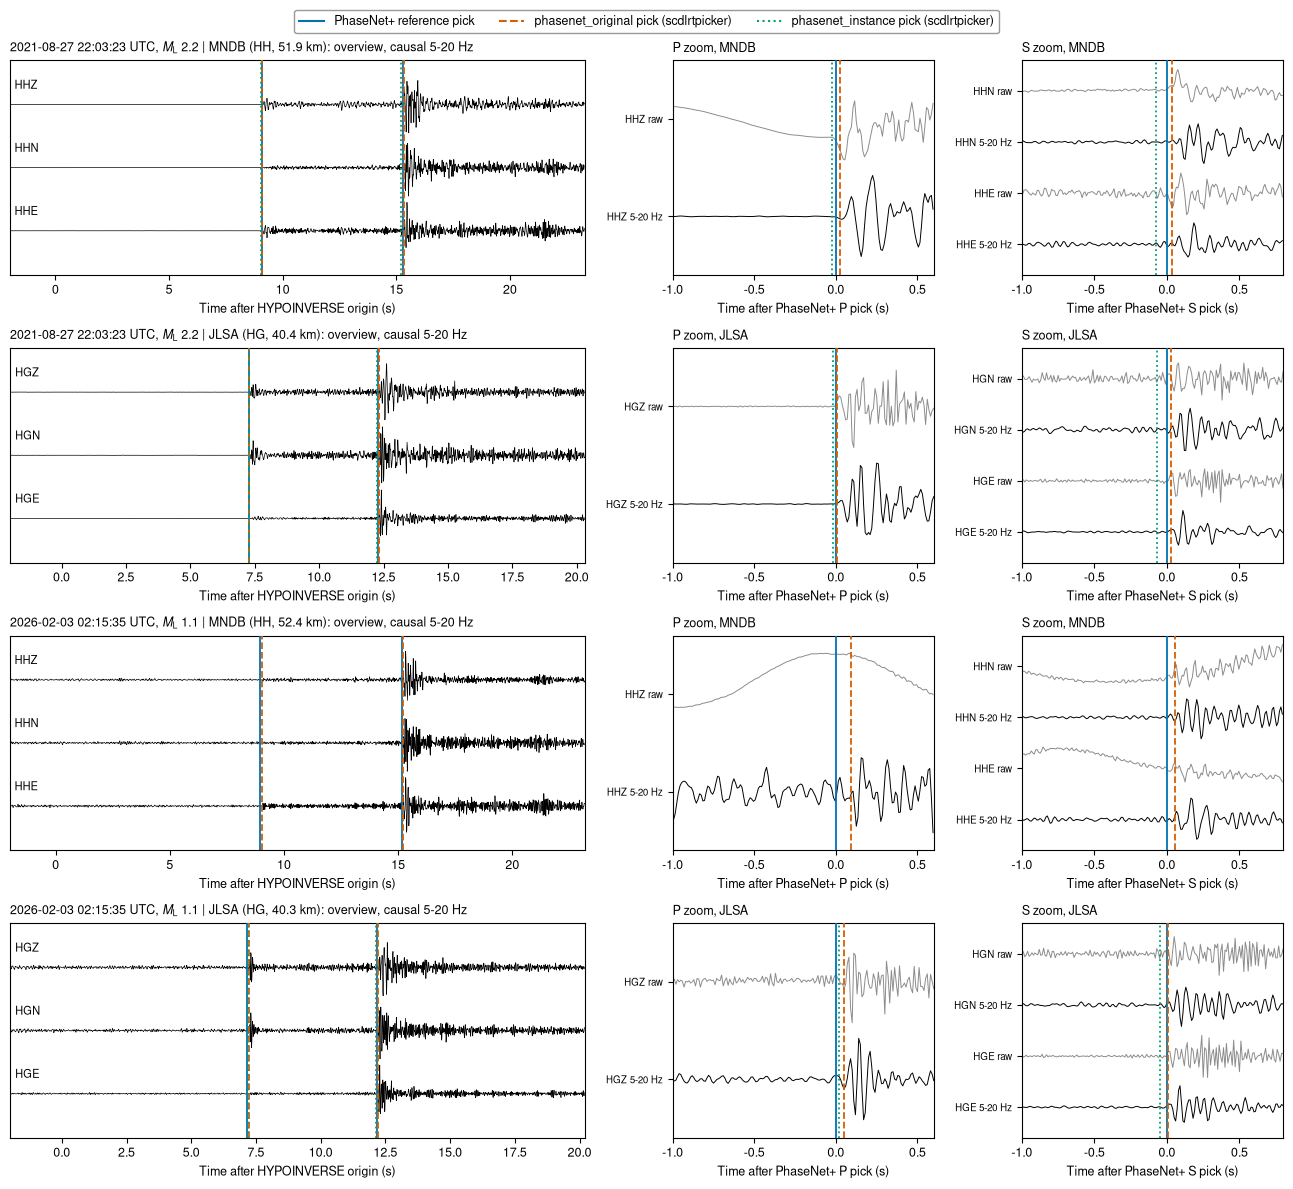

In [3]:
def load3(k, s, sen):
    st=obspy.read(f'{RUN09}/input/{k}_sorted.mseed')
    st=st.select(station=s, channel=f'{sen}?')
    st.merge(method=0)
    out={}
    for c in 'ZNE':
        tr=st.select(channel=f'{sen}{c}')[0].copy()
        tr.data=tr.data.astype(float)
        tr.data-=tr.data.mean()
        raw=tr.copy()
        tr.filter('bandpass', freqmin=BAND[0], freqmax=BAND[1], corners=4, zerophase=False)
        out[c]=(raw, tr)
    return out

def norm_in(tr, t0, t1):
    seg=tr.slice(t0, t1)
    x=seg.data
    t=np.arange(seg.stats.npts) / seg.stats.sampling_rate + (seg.stats.starttime - t0)
    a=np.max(np.abs(x)) if len(x) else 1.0
    return t, x / (a if a > 0 else 1.0)

def mark(ax, t, ref0, color, ls, lw=1.3):
    ax.axvline(t - ref0, color=color, ls=ls, lw=lw, zorder=5)

fig, axes=plt.subplots(len(examples), 3, figsize=(13, 3.0 * len(examples)), gridspec_kw={'width_ratios': [2.2, 1, 1]})
for row, (k, s, sen, dist) in enumerate(examples):
    o=obspy.UTCDateTime(hyp.loc[k, 'origin_time'])
    w=load3(k, s, sen)
    rr=ref[(ref.kma_id == k) & (ref.station == s)]
    tP=obspy.UTCDateTime(rr[rr.phase == 'P'].time.iloc[0])
    tS=obspy.UTCDateTime(rr[rr.phase == 'S'].time.iloc[0])
    picks={m: dl[m][k][dl[m][k].station == s] for m in MODELS}
    ax=axes[row, 0]
    t0, t1=o - 2.0, tS + 8.0
    for i, c in enumerate('ZNE'):
        t, x=norm_in(w[c][1], t0, t1)
        ax.plot(t - 2.0, x * 0.45 + (2 - i), color='k', lw=0.5)
        ax.text(-1.8, 2 - i + 0.25, f'{sen}{c}', fontsize=8)
    for ph, tt in (('P', tP), ('S', tS)):
        mark(ax, tt, o, *REF_STYLE)
    for m, (col, ls) in MODELS.items():
        for x in picks[m].itertuples():
            mark(ax, x.time, o, col, ls)
    ax.set_xlim(-2.0, t1 - o)
    ax.set_ylim(-0.7, 2.7)
    ax.set_yticks([])
    ax.set_xlabel('Time after HYPOINVERSE origin (s)')
    ml=idm.loc[k, 'kma_ml']
    ax.set_title(f'{o.strftime("%Y-%m-%d %H:%M:%S")} UTC, $\\mathit{{M}}_{{\\mathrm{{L}}}}$ {ml:.1f} | '
                 f'{s} ({sen}, {dist:.1f} km): overview, causal {BAND[0]:.0f}-{BAND[1]:.0f} Hz', fontsize=9, loc='left')
    for col, (ph, tt, comps, zz) in enumerate((('P', tP, 'Z', P_ZOOM), ('S', tS, 'NE', S_ZOOM)), start=1):
        ax=axes[row, col]
        a0, a1=tt + zz[0], tt + zz[1]
        y=0
        labels=[]
        for c in comps:
            for kind, idx, colr in (('raw', 0, '0.55'), (f'{BAND[0]:.0f}-{BAND[1]:.0f} Hz', 1, 'k')):
                t, x=norm_in(w[c][idx], a0, a1)
                ax.plot(t + zz[0], x * 0.42 - y, color=colr, lw=0.7)
                labels.append((-y, f'{sen}{c} {kind}'))
                y+=1
        mark(ax, tt, tt, *REF_STYLE)
        for m, (colr, ls) in MODELS.items():
            q=picks[m][picks[m].phase == ph]
            for x in q.itertuples():
                if a0 <= x.time <= a1:
                    mark(ax, x.time, tt, colr, ls)
        ax.set_xlim(zz)
        ax.set_ylim(-y + 0.4, 0.6)
        ax.set_yticks([v for v, _ in labels])
        ax.set_yticklabels([l for _, l in labels], fontsize=7)
        ax.set_xlabel(f'Time after PhaseNet+ {ph} pick (s)')
        ax.set_title(f'{ph} zoom, {s}', fontsize=9, loc='left')
handles=[plt.Line2D([], [], color=REF_STYLE[0], ls=REF_STYLE[1], lw=1.5, label='PhaseNet+ reference pick')]
handles+=[plt.Line2D([], [], color=c, ls=l, lw=1.5, label=f'{m} pick (scdlrtpicker)') for m, (c, l) in MODELS.items()]
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.canvas.draw()
r=fig.canvas.get_renderer()
ytop=max(a.get_tightbbox(r).y1 for a in axes.ravel()) / fig.bbox.height
leg=fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, ytop + 0.002), ncol=3, frameon=True, fontsize=9)
leg.set_zorder(50)
os.makedirs(os.path.dirname(FIG), exist_ok=True)
fig.savefig(FIG + '.png', dpi=150, bbox_inches='tight')
fig.savefig(FIG + '.pdf', bbox_inches='tight')
plt.show();

In [4]:
summary=sel[['event', 'ML', 'station', 'sensor', 'dist_km', 'ref_P_s_after_origin', 'phasenet_original_P_minus_ref_s',
             'phasenet_instance_P_minus_ref_s', 'ref_S_s_after_origin', 'phasenet_original_S_minus_ref_s',
             'phasenet_instance_S_minus_ref_s']]
print('DL minus PhaseNet+ pick time (s) at the 4 example stations (NaN = no DL pick of that phase there):')
print(summary.to_string(index=False))
n=sum(summary[c].notna().sum() for c in summary.columns if c.endswith('minus_ref_s'))
big=sum((summary[c].abs() > 0.05).sum() for c in summary.columns if c.endswith('minus_ref_s'))
print(f'{n} DL picks shown next to a PhaseNet+ pick; {big} of them differ by more than 0.05 s.')
print('figure:', FIG + '.png')

DL minus PhaseNet+ pick time (s) at the 4 example stations (NaN = no DL pick of that phase there):
         event  ML station sensor  dist_km  ref_P_s_after_origin  phasenet_original_P_minus_ref_s  phasenet_instance_P_minus_ref_s  ref_S_s_after_origin  phasenet_original_S_minus_ref_s  phasenet_instance_S_minus_ref_s
20210827220322 2.2    MNDB     HH     51.9                 9.083                            0.025                           -0.025                15.283                            0.035                           -0.075
20210827220322 2.2    JLSA     HG     40.4                 7.283                            0.010                           -0.020                12.303                            0.030                           -0.070
20260203021535 1.1    MNDB     HH     52.4                 8.953                            0.095                              NaN                15.163                            0.055                              NaN
20260203021535 1.1    JLS

## Signal-to-noise ratio at every pick shown

SNR = 10 log10 of the mean power in [t, t + 1 s] over the mean power in [t - 3 s, t - 0.5 s], on the causal
5-20 Hz trace: vertical for P, both horizontals together for S (the same definition step 09 used).
It is computed at the PhaseNet+ time and at each DL pick time.

In [5]:
def snr_db(trs, t, sig=(0.0, 1.0), noi=(-3.0, -0.5)):
    ps=pn=0.0
    for tr in trs:
        s=tr.slice(t + sig[0], t + sig[1]).data
        n=tr.slice(t + noi[0], t + noi[1]).data
        ps+=np.mean(s ** 2)
        pn+=np.mean(n ** 2)
    return 10 * np.log10(ps / pn)

rows=[]
for k, s, sen, dist in examples:
    w=load3(k, s, sen)
    rr=ref[(ref.kma_id == k) & (ref.station == s)]
    for ph in ('P', 'S'):
        trs=[w['Z'][1]] if ph == 'P' else [w['N'][1], w['E'][1]]
        tref=obspy.UTCDateTime(rr[rr.phase == ph].time.iloc[0])
        d=dict(event=k, station=s, sensor=sen, phase=ph, snr_db_at_phasenet_plus=round(snr_db(trs, tref), 1))
        for m in MODELS:
            q=dl[m][k]
            q=q[(q.station == s) & (q.phase == ph)]
            d[f'snr_db_at_{m}']=round(snr_db(trs, q.time.iloc[0]), 1) if len(q) else np.nan
        rows.append(d)
snr=pd.DataFrame(rows)
print(snr.to_string(index=False))

         event station sensor phase  snr_db_at_phasenet_plus  snr_db_at_phasenet_original  snr_db_at_phasenet_instance
20210827220322    MNDB     HH     P                     40.7                         40.6                         40.4
20210827220322    MNDB     HH     S                     15.9                         15.9                         15.9
20210827220322    JLSA     HG     P                     35.6                         35.8                         35.5
20210827220322    JLSA     HG     S                     17.7                         17.7                         17.8
20260203021535    MNDB     HH     P                      5.3                          5.7                          NaN
20260203021535    MNDB     HH     S                     18.1                         18.0                          NaN
20260203021535    JLSA     HG     P                     13.5                         13.6                         13.5
20260203021535    JLSA     HG     S             

## The one unclear arrival: P at MNDB for the ML 1.1 event, in three bands

In the main figure the P onset at MNDB (HH, 52 km) for the ML 1.1 event is not visible above the noise in the
5-20 Hz trace. Here the three components are shown in three causal bands (2-8, 5-20 and 10-40 Hz), from 2 s
before to 1.5 s after the PhaseNet+ P pick, each trace scaled to its own peak in that window, with the band SNR
at the PhaseNet+ and phasenet_original times.

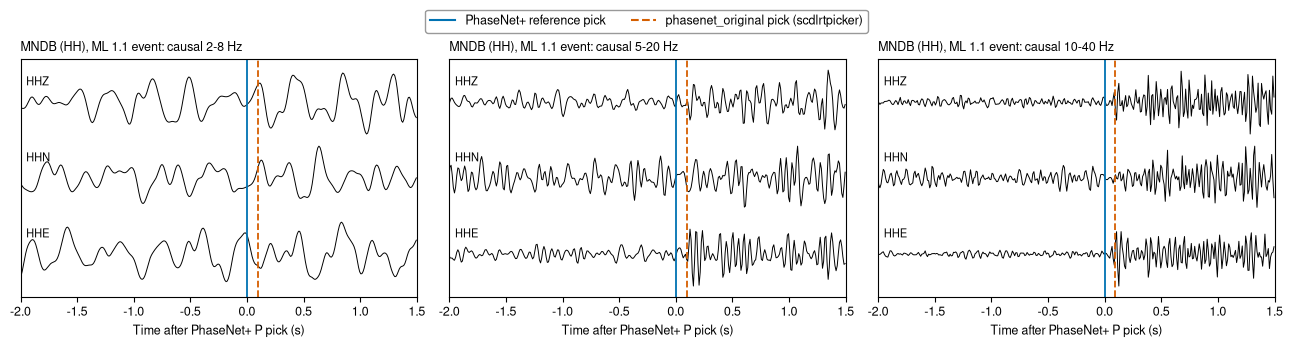

    band  snr_db_Z_at_phasenet_plus  snr_db_Z_at_phasenet_original
  2-8 Hz                        2.4                            3.1
 5-20 Hz                        5.3                            5.7
10-40 Hz                       12.8                           12.9


In [6]:
k, s, sen=EVENTS[1], 'MNDB', 'HH'
bands=[(2.0, 8.0), (5.0, 20.0), (10.0, 40.0)]
st=obspy.read(f'{RUN09}/input/{k}_sorted.mseed').select(station=s, channel=f'{sen}?')
st.merge(method=0)
rr=ref[(ref.kma_id == k) & (ref.station == s)]
tP=obspy.UTCDateTime(rr[rr.phase == 'P'].time.iloc[0])
qo=dl['phasenet_original'][k]
qo=qo[(qo.station == s) & (qo.phase == 'P')]
tO=qo.time.iloc[0] if len(qo) else None
fig2, axs=plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
brow=[]
for ax, (f0, f1) in zip(axs, bands):
    for i, c in enumerate('ZNE'):
        tr=st.select(channel=f'{sen}{c}')[0].copy()
        tr.data=tr.data.astype(float) - tr.data.mean()
        tr.filter('bandpass', freqmin=f0, freqmax=f1, corners=4, zerophase=False)
        t, x=norm_in(tr, tP - 2.0, tP + 1.5)
        ax.plot(t - 2.0, x * 0.42 - i, color='k', lw=0.7)
        ax.text(-1.95, -i + 0.22, f'{sen}{c}', fontsize=8)
        if c == 'Z':
            brow.append(dict(band=f'{f0:.0f}-{f1:.0f} Hz', snr_db_Z_at_phasenet_plus=round(snr_db([tr], tP), 1),
                             snr_db_Z_at_phasenet_original=round(snr_db([tr], tO), 1) if tO else np.nan))
    ax.axvline(0.0, color=REF_STYLE[0], ls=REF_STYLE[1], lw=1.3)
    if tO is not None:
        ax.axvline(tO - tP, color=MODELS['phasenet_original'][0], ls=MODELS['phasenet_original'][1], lw=1.3)
    ax.set_xlim(-2.0, 1.5)
    ax.set_yticks([])
    ax.set_xlabel('Time after PhaseNet+ P pick (s)')
    ax.set_title(f'{s} ({sen}), ML 1.1 event: causal {f0:.0f}-{f1:.0f} Hz', fontsize=9, loc='left')
fig2.tight_layout(rect=(0, 0, 1, 0.9))
fig2.canvas.draw()
r2=fig2.canvas.get_renderer()
ytop2=max(a.get_tightbbox(r2).y1 for a in axs) / fig2.bbox.height
leg2=fig2.legend(handles=handles[:2], loc='lower center', bbox_to_anchor=(0.5, ytop2 + 0.005), ncol=2, frameon=True, fontsize=9)
leg2.set_zorder(50)
fig2.savefig(FIG + '_mndb_small_event_P_bands.png', dpi=150, bbox_inches='tight')
plt.show();
print(pd.DataFrame(brow).to_string(index=False))

## Summary (computed from the tables above)

In [7]:
cols=[c for c in sel.columns if c.endswith('minus_ref_s')]
vals=sel[cols].to_numpy(dtype=float).ravel()
vals=vals[np.isfinite(vals)]
print(f'examples: {len(examples)} (events {EVENTS}; stations {sorted(set(s for _, s, _, _ in examples))})')
print(f'DL picks next to a PhaseNet+ pick: {len(vals)}; |DL - PhaseNet+| median {np.median(np.abs(vals)):.3f} s, '
      f'max {np.max(np.abs(vals)):.3f} s; within 0.05 s: {np.sum(np.abs(vals) <= 0.05 + 1e-9)} of {len(vals)}')
for m in MODELS:
    for ph in ('P', 'S'):
        v=sel[f'{m}_{ph}_minus_ref_s'].to_numpy(dtype=float)
        print(f'  {m} {ph}: DL - PhaseNet+ = {np.round(v, 3).tolist()} s (NaN = no DL pick)')
print(f'SNR at the PhaseNet+ picks (5-20 Hz): min {snr.snr_db_at_phasenet_plus.min():.1f} dB, '
      f'max {snr.snr_db_at_phasenet_plus.max():.1f} dB; lowest = '
      f'{snr.loc[snr.snr_db_at_phasenet_plus.idxmin(), ["event", "station", "phase"]].tolist()}')
b=pd.DataFrame(brow)
print('MNDB, ML 1.1 event, P: SNR on Z at the PhaseNet+ / phasenet_original times by band:',
      dict(zip(b.band, zip(b.snr_db_Z_at_phasenet_plus, b.snr_db_Z_at_phasenet_original))))

examples: 4 (events ['20210827220322', '20260203021535']; stations ['JLSA', 'MNDB'])
DL picks next to a PhaseNet+ pick: 14; |DL - PhaseNet+| median 0.033 s, max 0.095 s; within 0.05 s: 10 of 14
  phasenet_original P: DL - PhaseNet+ = [0.025, 0.01, 0.095, 0.05] s (NaN = no DL pick)
  phasenet_original S: DL - PhaseNet+ = [0.035, 0.03, 0.055, 0.01] s (NaN = no DL pick)
  phasenet_instance P: DL - PhaseNet+ = [-0.025, -0.02, nan, 0.02] s (NaN = no DL pick)
  phasenet_instance S: DL - PhaseNet+ = [-0.075, -0.07, nan, -0.05] s (NaN = no DL pick)
SNR at the PhaseNet+ picks (5-20 Hz): min 5.3 dB, max 40.7 dB; lowest = ['20260203021535', 'MNDB', 'P']
MNDB, ML 1.1 event, P: SNR on Z at the PhaseNet+ / phasenet_original times by band: {'2-8 Hz': (2.4, 3.1), '5-20 Hz': (5.3, 5.7), '10-40 Hz': (12.8, 12.9)}


## Take-homes (from looking at the figures and the numbers above)

1. **phasenet_original picks sit on the arrivals.** In all 8 arrivals shown (4 stations x P and S), its pick lies
   at the first visible energy or within the first half-cycle after it (0.01-0.055 s after the PhaseNet+ pick,
   and 0.095 s in the case of point 3).
2. **phasenet_instance's S picks sit 0.05-0.075 s ahead of the visible S onset**, in the pre-S noise, at all
   three stations where it picked S. This is the early S bias step 09 reported (mean -0.072 s against PhaseNet+).
   Its P picks are within 0.025 s of PhaseNet+. It made no pick at MNDB for the ML 1.1 event.
3. **The one weak arrival (P at MNDB, HH, 52 km, ML 1.1 event)** has an SNR of only about 5 dB at 5-20 Hz, where
   the onset cannot be seen. At 10-40 Hz (about 13 dB) the first energy above the noise starts at the
   phasenet_original pick (+0.095 s); the PhaseNet+ pick lies about 0.09 s earlier, in the noise. Here the
   reference, not the DL pick, looks off. PhaseNet+ is not ground truth.
4. **Caveat:** 4 examples chosen by a fixed distance rule (closest to 40 km) show what typical picks look like.
   They cannot confirm the statistics of all 3651 DL picks; the far-station "P on the S wave" and noise picks
   that step 09 lists are, by construction, not among them.